# Task 1 — N-Queen

Đánh giá mã hóa CNF với Glucose3 và so sánh hai cách chọn biến trong Min-Conflicts.
Các nghiệm được kiểm tra lại trên bàn cờ. Các thời gian được đo trên máy chạy notebook.

In [1]:
import sys
import random
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt
import pandas as pd

current = Path.cwd().resolve()
for candidate in (current, *current.parents):
    if (candidate / "task1" / "board.py").exists():
        source_dir = candidate
        break
    if (candidate / "source" / "task1" / "board.py").exists():
        source_dir = candidate / "source"
        break
else:
    raise RuntimeError("Không tìm thấy thư mục source/task1")
sys.path.insert(0, str(source_dir))

from task1.board import NQueenBoard
from task1.cnf_encoder import NQueenCNFEncoder
from task1.sat_solver import Glucose3NQueenSolver
from task1.min_conflicts import MinConflictsSolver, RandomConflictedSelector, TabuMaxConflictSelector

figure_dir = source_dir.parent / "report" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

## Glucose3

Mỗi ô có một biến logic. Số mệnh đề và thời gian được ghi cho từng kích thước.
Thời gian solver bao gồm khởi tạo, nạp mệnh đề, giải và lấy mô hình.

In [2]:
sat_sizes = [4, 8, 12, 16, 20, 25, 30, 35, 40, 50, 60]
sat_rows = []
for n in sat_sizes:
    result = Glucose3NQueenSolver().solve(n)
    assert result.satisfiable and result.board.is_valid_solution()
    assert result.num_clauses == NQueenCNFEncoder(n).theoretical_clause_count()
    sat_rows.append({
        "N": n, "Variables": result.num_variables, "Clauses": result.num_clauses,
        "Encoding ms": result.encoding_time_sec * 1000,
        "Solver ms": result.solve_time_sec * 1000,
    })
sat_results = pd.DataFrame(sat_rows)
sat_results.round(2)

,N,Variables,Clauses,Encoding ms,Solver ms
0,4,16,84,0.10,0.72
1,8,64,744,0.47,0.62
2,12,144,2620,0.65,1.92
3,16,256,6352,1.67,16.60
4,20,400,12580,3.17,6.13
5,25,625,24850,4.19,10.89
6,30,900,43270,7.80,17.90
7,35,1225,69090,8.95,47.01
8,40,1600,103560,107.11,67.35
9,50,2500,203450,40.81,67.66


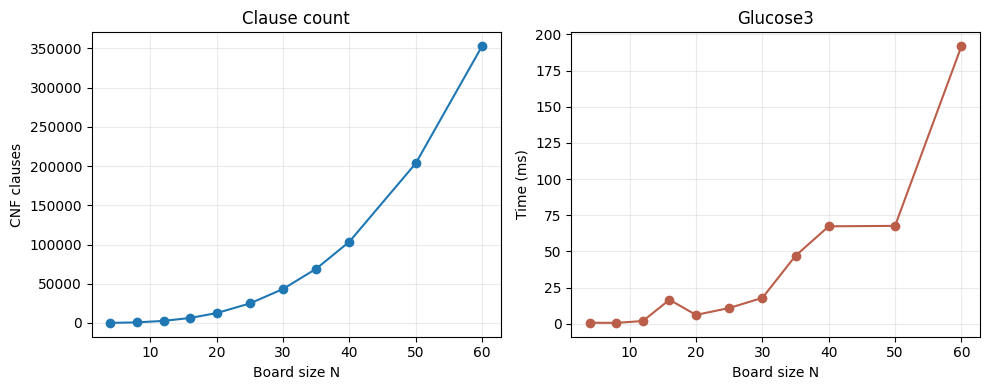

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(sat_results["N"], sat_results["Clauses"], marker="o")
axes[0].set(xlabel="Board size N", ylabel="CNF clauses", title="Clause count")
axes[1].plot(sat_results["N"], sat_results["Solver ms"], marker="o", color="#ba5e49")
axes[1].set(xlabel="Board size N", ylabel="Time (ms)", title="Glucose3")
for axis in axes:
    axis.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(figure_dir / "task1_glucose3_scaling.png", dpi=150)
plt.show()

## Min-Conflicts

Hai phương pháp dùng cùng 30 bàn cờ khởi tạo cho mỗi kích thước, giới hạn 2.500 bước.
Số bước và thời gian trung bình tính trên tất cả lượt chạy, kể cả lượt chưa tìm được nghiệm.

In [4]:
sizes = [8, 16, 32, 64, 100, 150]
trials = 30
max_steps = 2500
local_rows = []
for n in sizes:
    boards = [NQueenBoard.from_random(n, random.Random(2026 + n * 131 + i)) for i in range(trials)]
    for name, selector in [("Random", RandomConflictedSelector()), ("Max-conflict + Tabu", TabuMaxConflictSelector())]:
        solver = MinConflictsSolver(selector, max_steps=max_steps)
        runs = [solver.solve(n, initial_board=board, seed=9000 + i) for i, board in enumerate(boards)]
        local_rows.append({
            "N": n, "Method": name,
            "Success %": 100 * sum(run.solved and run.board.is_valid_solution() for run in runs) / trials,
            "Mean steps": mean(run.steps for run in runs),
            "Mean ms": 1000 * mean(run.elapsed_sec for run in runs),
        })
local_results = pd.DataFrame(local_rows)
local_results.round(2)

,N,Method,Success %,Mean steps,Mean ms
0,8,Random,100.00,44.37,0.38
1,8,Max-conflict + Tabu,93.33,181.67,2.25
2,16,Random,100.00,96.00,1.79
3,16,Max-conflict + Tabu,100.00,30.73,1.16
4,32,Random,100.00,90.57,2.31
5,32,Max-conflict + Tabu,100.00,45.97,1.43
6,64,Random,100.00,107.17,4.14
7,64,Max-conflict + Tabu,100.00,63.27,2.80
8,100,Random,100.00,138.67,9.49
9,100,Max-conflict + Tabu,100.00,88.40,8.52


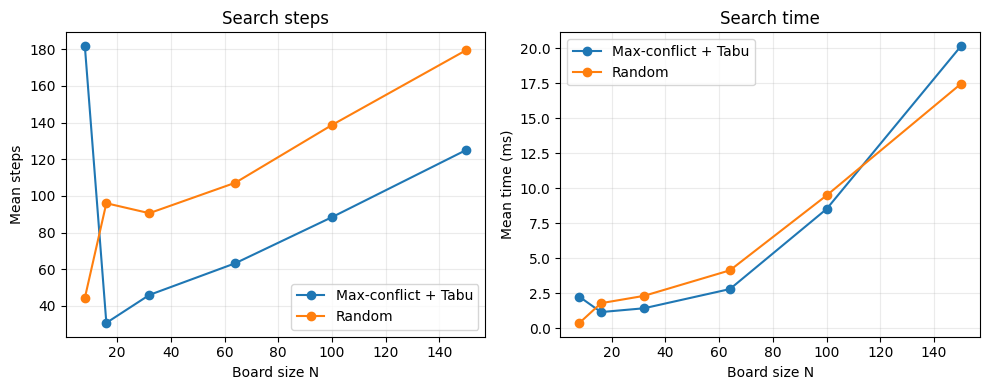

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for method, group in local_results.groupby("Method"):
    axes[0].plot(group["N"], group["Mean steps"], marker="o", label=method)
    axes[1].plot(group["N"], group["Mean ms"], marker="o", label=method)
axes[0].set(xlabel="Board size N", ylabel="Mean steps", title="Search steps")
axes[1].set(xlabel="Board size N", ylabel="Mean time (ms)", title="Search time")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend()
fig.tight_layout()
fig.savefig(figure_dir / "task1_min_conflicts_comparison.png", dpi=150)
plt.show()